# Seminar 5. Second-Order and Quasi-Newton Methods

Checks and NumPy experiments for Newton's method, its safeguards, Gauss–Newton, BFGS and L-BFGS.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

SEED = 42
TOPIC = "Second-Order and Quasi-Newton Methods"
SEMINAR = "05"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-12):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    integer = isinstance(computed, (int, Fr)) and Fr(computed).denominator == 1
    typed = float(computed) if integer else float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          1e-8 * max(1, abs(float(computed))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
          not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


def s6(v):
    """Six decimals, as the page prints them."""
    text = f"{float(v):.6f}"
    return "0.000000" if text == "-0.000000" else text


def fixed(v, n):
    return f"{float(v):.{n}f}"


def g5(v):
    return f"{float(v):.5g}"


def sci(v, digits):
    """v as 'm \\cdot 10^{e}' in TeX with the given number of significant digits."""
    mantissa, exponent = f"{float(v):.{digits - 1}e}".split("e")
    return f"{mantissa} \\cdot 10^{{{int(exponent)}}}"


def dec(q):
    """The exact decimal of a Fraction whose denominator has no prime factors other than 2 and 5."""
    q = Fr(q)
    sign, q = ("-" if q < 0 else ""), abs(q)
    n = 0
    while (q * 10**n).denominator != 1:
        n += 1
        assert n < 60, q
    digits = str(int(q * 10**n)).rjust(n + 1, "0")
    return sign + (digits if n == 0 else digits[:-n] + "." + digits[-n:])


def tfrac(q):
    return f"\\tfrac{{{q.numerator}}}{{{q.denominator}}}"


def pow10(q):
    e = round(math.log10(q))
    assert Fr(10) ** e == q, q
    return f"10^{{{e}}}"


def first_power_below(ratio, gap):
    """The least k with ratio**k <= gap, for Fractions 0 < ratio < 1, checked in integers."""
    k = max(1, math.ceil(math.log(gap) / math.log(ratio)) - 2)
    while ratio ** (k - 1) <= gap:
        k -= 1
    while ratio**k > gap:
        k += 1
    return k


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/05. Second-Order and Quasi-Newton Methods.ipynb
data leaves: 249 public, 107 students


## 2. NumPy methods

Each method returns an iterate and a history with the objective, the gradient norm and the numbers of function, gradient and Hessian calls.

In [2]:
def armijo(f, x, fx, g, p, c=1e-4, shrink=0.5, max_halvings=60):
    slope = g @ p
    if not slope < 0:
        raise ValueError('not a descent direction')
    alpha, calls = 1.0, 0
    for _ in range(max_halvings + 1):
        trial = float(f(x + alpha * p))
        calls += 1
        if math.isfinite(trial) and trial <= fx + c * alpha * slope:
            return alpha, trial, calls
        alpha *= shrink
    raise RuntimeError('line search failed')

In [3]:
def newton(f, grad, hess, x0, tol=1e-8, max_iter=100, damped=False, growth=10.0):
    """Full Newton, or with damped=True a shift lam*I until Cholesky succeeds and Armijo backtracking."""
    x = np.array(x0, dtype=float, copy=True)
    fx = float(f(x))
    history = {'x': [x.copy()], 'f': [fx], 'grad_norm': [], 'alpha': [], 'lam': [],
               'f_calls': 1, 'g_calls': 0, 'h_calls': 0}
    for k in range(max_iter):
        g, H = grad(x), hess(x)
        history['g_calls'] += 1
        history['h_calls'] += 1
        history['grad_norm'].append(float(np.linalg.norm(g)))
        if history['grad_norm'][-1] <= tol:
            break
        lam = 0.0
        while damped:
            try:
                np.linalg.cholesky(H + lam * np.eye(len(x)))
                break
            except np.linalg.LinAlgError:
                lam = max(growth * lam, 1e-8)
        p = np.linalg.solve(H + lam * np.eye(len(x)), -g)
        if damped:
            alpha, fx, calls = armijo(f, x, fx, g, p)
            history['f_calls'] += calls
        else:
            alpha, fx = 1.0, float(f(x + p))
            history['f_calls'] += 1
        x = x + alpha * p
        if not np.all(np.isfinite(x)) or not math.isfinite(fx):
            raise FloatingPointError('nonfinite iterate')
        history['x'].append(x.copy())
        history['f'].append(fx)
        history['alpha'].append(alpha)
        history['lam'].append(lam)
    return x, history

In [4]:
def bfgs_update(G, s, y, eps=1e-12):
    """Inverse BFGS update; the pair is skipped unless y's > eps |y| |s|."""
    ys = y @ s
    if ys <= eps * np.linalg.norm(y) * np.linalg.norm(s):
        return G.copy(), False
    rho = 1.0 / ys
    V = np.eye(len(s)) - rho * np.outer(s, y)
    return V @ G @ V.T + rho * np.outer(s, s), True


def two_loop(g, pairs, gamma):
    q = g.copy()
    alphas = []
    for s, y in reversed(pairs):
        a = (s @ q) / (y @ s)
        alphas.append(a)
        q = q - a * y
    r = gamma * q
    for (s, y), a in zip(pairs, reversed(alphas)):
        b = (y @ r) / (y @ s)
        r = r + s * (a - b)
    return -r


def quasi_newton(f, grad, x0, tol=1e-8, max_iter=10_000, memory=None):
    """BFGS with a dense inverse estimate, or L-BFGS keeping the last `memory` pairs."""
    x = np.array(x0, dtype=float, copy=True)
    fx, g = float(f(x)), grad(x)
    G, pairs, gamma = np.eye(len(x)), [], 1.0
    history = {'x': [x.copy()], 'f': [fx], 'grad_norm': [float(np.linalg.norm(g))], 'alpha': [],
               'skipped': 0, 'f_calls': 1, 'g_calls': 1}
    for k in range(max_iter):
        if history['grad_norm'][-1] <= tol:
            break
        p = -G @ g if memory is None else two_loop(g, pairs, gamma)
        alpha, f_new, calls = armijo(f, x, fx, g, p)
        history['f_calls'] += calls
        x_new = x + alpha * p
        g_new = grad(x_new)
        history['g_calls'] += 1
        s, y = x_new - x, g_new - g
        if memory is None:
            G, ok = bfgs_update(G, s, y)
        else:
            ok = y @ s > 1e-12 * np.linalg.norm(y) * np.linalg.norm(s)
            if ok:
                pairs = (pairs + [(s, y)])[-memory:]
                gamma = (s @ y) / (y @ y)
        history['skipped'] += not ok
        x, fx, g = x_new, f_new, g_new
        history['x'].append(x.copy())
        history['f'].append(fx)
        history['grad_norm'].append(float(np.linalg.norm(g)))
        history['alpha'].append(alpha)
    return x, history


def gradient_descent(f, grad, x0, tol=1e-8, max_iter=100_000):
    x = np.array(x0, dtype=float, copy=True)
    fx, g = float(f(x)), grad(x)
    history = {'x': [x.copy()], 'f': [fx], 'grad_norm': [float(np.linalg.norm(g))], 'f_calls': 1, 'g_calls': 1}
    for k in range(max_iter):
        if history['grad_norm'][-1] <= tol:
            break
        alpha, fx, calls = armijo(f, x, fx, g, -g)
        history['f_calls'] += calls
        x = x - alpha * g
        g = grad(x)
        history['g_calls'] += 1
        history['x'].append(x.copy())
        history['f'].append(fx)
        history['grad_norm'].append(float(np.linalg.norm(g)))
    return x, history

In [5]:
def rosenbrock(a=100):
    f = lambda v: a * (v[1] - v[0] ** 2) ** 2 + (1 - v[0]) ** 2
    grad = lambda v: np.array([-4 * a * v[0] * (v[1] - v[0] ** 2) - 2 * (1 - v[0]), 2 * a * (v[1] - v[0] ** 2)])
    hess = lambda v: np.array([[12 * a * v[0] ** 2 - 4 * a * v[1] + 2, -4 * a * v[0]], [-4 * a * v[0], 2 * a]])
    return f, grad, hess


saddle = (lambda v: 0.5 * v[0] ** 2 - v[1] ** 2 + 0.25 * v[1] ** 4,
          lambda v: np.array([v[0], -2 * v[1] + v[1] ** 3]),
          lambda v: np.diag([1.0, -2 + 3 * v[1] ** 2]))


def logistic(X, y, reg):
    N, n = X.shape
    sigma = lambda z: 0.5 * (1 + np.tanh(z / 2))
    f = lambda w: float(np.mean(np.logaddexp(0, X @ w) - y * (X @ w)) + reg / 2 * w @ w)
    grad = lambda w: X.T @ (sigma(X @ w) - y) / N + reg * w
    hess = lambda w: X.T @ ((sigma(X @ w) * (1 - sigma(X @ w)))[:, None] * X) / N + reg * np.eye(n)
    hvp = lambda w, v: X.T @ (sigma(X @ w) * (1 - sigma(X @ w)) * (X @ v)) / N + reg * v
    return f, grad, hess, hvp

## 3. Small exact examples

Newton's step solves $Hp=-g$; BFGS updates $G$ so that $G^+y=s$. Exact values use `Fraction` wherever the arithmetic allows it.

In [6]:
xs, ys_ = sp.symbols('x y')
a = 100
fsym = a * (ys_ - xs ** 2) ** 2 + (1 - xs) ** 2
gsym = sp.Matrix([fsym]).jacobian([xs, ys_]).T
Hsym = sp.hessian(fsym, (xs, ys_))
x0 = sp.Matrix([0, 0])
ev = lambda e, v: e.subs({xs: v[0], ys_: v[1]})
p0 = Hsym.subs({xs: 0, ys_: 0}).LUsolve(-ev(gsym, x0))
x1 = x0 + p0
p1 = ev(Hsym, x1).LUsolve(-ev(gsym, x1))
x2 = x1 + p1
expect('A1.params', {'a': a, 'x0': [0, 0], 'c': Fr(1, 10**4)})
for key, value in {'g0': ev(gsym, x0), 'H0': ev(Hsym, x0), 'p0': p0, 'x1': x1, 'g1': ev(gsym, x1),
                   'H1': ev(Hsym, x1), 'p1': p1, 'x2': x2}.items():
    expect(f'A1.{key}', np.array(value.tolist(), dtype=float).squeeze())
for k, point in enumerate((x0, x1, x2)):
    expect(f'A1.f{k}', int(ev(fsym, point)))
slope = (ev(gsym, x0).T * p0)[0]
trials, alpha = [], Fr(1)
while True:
    trial = Fr(str(ev(fsym, x0 + sp.Rational(alpha.numerator, alpha.denominator) * p0)))
    trials.append((alpha, trial))
    if trial <= int(ev(fsym, x0)) + Fr(1, 10**4) * alpha * int(slope):
        break
    alpha /= 2
expect('A1.slope', int(slope))
expect('A1.trial', {'alpha': [a_ for a_, _ in trials], 'f': [t for _, t in trials]})
expect('A1.alpha', alpha)
expect('A1.xdamped', [alpha, 0])
expect_answer('A1.f1', ev(fsym, x1))
expect_answer('A1.alpha', alpha)
expect_answer('A1.fdamped', trials[-1][1])
f, grad, hess = rosenbrock()
_, h = newton(f, grad, hess, [0, 0], max_iter=2)
check('A1: NumPy Newton repeats the exact iterates', h['x'], [[0, 0], [1, 0], [1, 1]], 1e-12)
_, h = newton(f, grad, hess, [0, 0], max_iter=1, damped=True)
check('A1: NumPy damped Newton accepts the same step', h['alpha'], [0.25])
section('A1')

A1: A1.params                                         {a: 100, x0: [0, 0], c: 1/10000}          ok
A1: A1.g0                                             [-2, 0]                                   ok
A1: A1.H0                                             [[2, 0], [0, 200]]                        ok
A1: A1.p0                                             [1, 0]                                    ok
A1: A1.x1                                             [1, 0]                                    ok
A1: A1.g1                                             [400, -200]                               ok
A1: A1.H1                                             [[1202, -400], [-400, 200]]               ok
A1: A1.p1                                             [0, 1]                                    ok
A1: A1.x2                                             [1, 1]                                    ok
A1: A1.f0                                             1                                         ok
A1: A1.f1 

In [7]:
Q = sp.Matrix([[4, 1], [1, 2]])
b = sp.Matrix([1, -1])
x0 = sp.Matrix([2, 0])
g0 = Q * x0 - b
p0 = Q.LUsolve(-g0)
x1 = x0 + p0
eig = sorted(Q.eigenvals(), key=lambda e: float(e))
kappa = eig[1] / eig[0]
expect('A2.params', {'Q': [[4, 1], [1, 2]], 'b': [1, -1], 'x0': [2, 0]})
for key, value in {'g0': g0, 'p0': p0, 'x1': x1}.items():
    expect(f'A2.{key}', np.array(value.tolist(), dtype=float).squeeze())
expect('A2.eig', [float(e) for e in eig])
expect('A2.kappa', float(kappa))
expect('A2.rate', float((kappa - 1) / (kappa + 1)))
check('A2: x1 is the solution of Qx = b', list(Q * x1 - b), [0, 0])
check('A2: x1 does not depend on the start', list(x0 + Q.LUsolve(-(Q * x0 - b)) - Q.LUsolve(b)), [0, 0])
check('A2: kappa is (3 + sqrt 2)/(3 - sqrt 2)', float(kappa), (3 + math.sqrt(2)) / (3 - math.sqrt(2)), 1e-12)
expect_answer('A2.first', float(x1[0]))
expect_answer('A2.second', float(x1[1]))
expect_answer('A2.kappa', float(kappa))
section('A2')

A2: A2.params                                        {Q: [[4, 1], [1, 2]], b: [1, -1], x0:...  ok
A2: A2.g0                                            [7, 3]                                    ok
A2: A2.p0                                            [-1.571428571, -0.7142857143]             ok
A2: A2.x1                                            [0.4285714286, -0.7142857143]             ok
A2: A2.eig                                           [1.585786438, 4.414213562]                ok
A2: A2.kappa                                         2.783611625                               ok
A2: A2.rate                                          0.4714045208                              ok
A2: x1 is the solution of Qx = b                     [0, 0]                                    ok
A2: x1 does not depend on the start                  [0, 0]                                    ok
A2: kappa is (3 + sqrt 2)/(3 - sqrt 2)               2.783611625                               ok
A2: answer first is 

In [8]:
x = sp.symbols('x', positive=True)
phi = sp.simplify(x - sp.diff(x - sp.log(x), x) / sp.diff(x - sp.log(x), x, 2))
check('A3: Newton map is 2x - x^2', sp.expand(phi - (2 * x - x ** 2)), 0)
check('A3: the error squares', sp.expand((1 - phi) - (1 - x) ** 2), 0)
iterates = [Fr(1, 2)]
for _ in range(3):
    iterates.append(2 * iterates[-1] - iterates[-1] ** 2)
steps = next(k for k in range(64) if Fr(1, 2) ** (2 ** k) <= Fr(1, 10 ** 12))
expect('A3.params', {'x0': Fr(1, 2), 'digits': 12, 'target': '10^{-12}'})
expect('A3.iterates', iterates)
expect('A3.errors', [1 - v for v in iterates])
expect('A3.x3', iterates[3])
expect('A3.steps', steps)
expect('A3.bound', 2)
expect('A3.far', Fr(5, 2))
expect('A3.outside', 2 * Fr(5, 2) - Fr(5, 2) ** 2)
check('A3: the start 2 lands on 0', 2 * 2 - 2 ** 2, 0)
expect_answer('A3.x3', iterates[3])
expect_answer('A3.steps', steps)
expect_answer('A3.bound', 2)
section('A3')

A3: Newton map is 2x - x^2                          0                                         ok
A3: the error squares                               0                                         ok
A3: A3.params                                       {x0: 1/2, digits: 12, target: 10^{-12}}   ok
A3: A3.iterates                                     [1/2, 3/4, 15/16, 255/256]                ok
A3: A3.errors                                       [1/2, 1/4, 1/16, 1/256]                   ok
A3: A3.x3                                           255/256                                   ok
A3: A3.steps                                        6                                         ok
A3: A3.bound                                        2                                         ok
A3: A3.far                                          5/2                                       ok
A3: A3.outside                                      -5/4                                      ok
A3: the start 2 lands on 0    

In [9]:
fq, gq, Hq = saddle
point = np.array([0, 0.5])
g = gq(point)
H = Hq(point)
pN = np.linalg.solve(H, -g)
lam_min = -np.linalg.eigvalsh(H).min()
preg = np.linalg.solve(H + 2 * np.eye(2), -g)
expect('B1.params', {'x': [0, 0.5], 'lam': 2, 'c': 1e-4})
values = {'g': g, 'H': H, 'pN': pN, 'slopeN': g @ pN, 'f0': fq(point), 'fN': fq(point + pN), 'lamMin': lam_min,
          'preg': preg, 'slopeReg': g @ preg, 'freg': fq(point + preg), 'armijoRhs': fq(point) + 1e-4 * g @ preg,
          'ymin': math.sqrt(2)}
for key, value in values.items():
    expect(f'B1.{key}', value)
check('B1: exact slope is 49/80', Fr(str(g @ pN)).limit_denominator(1000), Fr(49, 80))
check('B1: the full Newton step raises f', fq(point + pN) > fq(point), True)
check('B1: the regularized step passes Armijo', fq(point + preg) <= values['armijoRhs'], True)
check('B1: minimizers of the quartic in y', sorted(np.roots([1, 0, -2, 0]).real), [-math.sqrt(2), 0, math.sqrt(2)], 1e-12)
expect_answer('B1.slope', g @ pN)
expect_answer('B1.step', preg[1])
expect_answer('B1.freg', fq(point + preg))
section('B1')

B1: B1.params                                       {x: [0, 0.5], lam: 2, c: 0.0001}          ok
B1: B1.g                                            [0, -0.875]                               ok
B1: B1.H                                            [[1, 0], [0, -1.25]]                      ok
B1: B1.pN                                           [0, -0.7]                                 ok
B1: B1.slopeN                                       0.6125                                    ok
B1: B1.f0                                           -0.234375                                 ok
B1: B1.fN                                           -0.0396                                   ok
B1: B1.lamMin                                       1.25                                      ok
B1: B1.preg                                         [-0, 1.166666667]                         ok
B1: B1.slopeReg                                     -1.020833333                              ok
B1: B1.freg                   

In [10]:
phi = lambda x: 2 * x ** 3 / (3 * x ** 2 - 1)
sym = sp.symbols('x')
check('B2: Newton map', sp.simplify(sym - (sym ** 3 - sym) / (3 * sym ** 2 - 1) - 2 * sym ** 3 / (3 * sym ** 2 - 1)), 0)
x1 = phi(Fr(2, 5))
x2 = phi(x1)
threshold = 1 / math.sqrt(5)
expect('B2.params', {'x0': Fr(2, 5)})
expect('B2.x1', x1)
expect('B2.x2', x2)
expect('B2.threshold', threshold)
expect('B2.curvature0', -1)
check('B2: the two-cycle sits at 1/sqrt 5', phi(threshold), -threshold, 1e-12)
check('B2: starts inside shrink to the maximum',
      all(abs(phi(t)) < abs(t) for t in np.linspace(0.01, threshold - 1e-6, 200)), True)
x = 0.4
for _ in range(10):
    x = phi(x)
check('B2: iterates reach the maximum at 0', abs(x), 0, 1e-12)
expect_answer('B2.x1', x1)
expect_answer('B2.x2', x2)
expect_answer('B2.threshold', threshold)
section('B2')

B2: Newton map                                          0                                         ok
B2: B2.params                                           {x0: 2/5}                                 ok
B2: B2.x1                                               -16/65                                    ok
B2: B2.x2                                               8192/224705                               ok
B2: B2.threshold                                        0.4472135955                              ok
B2: B2.curvature0                                       -1                                        ok
B2: the two-cycle sits at 1/sqrt 5                      -0.4472135955                             ok
B2: starts inside shrink to the maximum                 True                                      ok
B2: iterates reach the maximum at 0                     0                                         ok
B2: answer x1 is a number spec                          [[tol, type, value], number]       

In [11]:
theta = Fr(1)
r = [theta ** 2 - 2, theta - 1]
J = [2 * theta, Fr(1)]
JtJ = sum(j * j for j in J)
Jtr = sum(j * ri for j, ri in zip(J, r))
extra = r[0] * 2
t = sp.symbols('t')
fsym = ((t ** 2 - 2) ** 2 + (t - 1) ** 2) / 2
check('B3: exact second derivative at 1', sp.diff(fsym, t, 2).subs(t, 1), JtJ + extra)
roots = [sp.nsimplify(v) for v in sp.solve(sp.diff(fsym, t), t)]
optimum = max(roots, key=lambda v: float(v))
check('B3: the minimizer is (1 + sqrt 3)/2', sp.simplify(optimum - (1 + sp.sqrt(3)) / 2), 0)
expect('B3.params', {'theta0': 1, 'lam': 1})
for key, value in {'r0': r, 'J0': J, 'JtJ': JtJ, 'Jtr': Jtr, 'extra': extra, 'hess': JtJ + extra,
                   'gn': theta - Jtr / JtJ, 'newton': theta - Jtr / (JtJ + extra), 'lm': theta - Jtr / (JtJ + 1),
                   'optimum': float(optimum)}.items():
    expect(f'B3.{key}', value)
expect_answer('B3.gn', theta - Jtr / JtJ)
expect_answer('B3.newton', theta - Jtr / (JtJ + extra))
expect_answer('B3.lm', theta - Jtr / (JtJ + 1))
section('B3')

B3: exact second derivative at 1                     3                                         ok
B3: the minimizer is (1 + sqrt 3)/2                  0                                         ok
B3: B3.params                                        {theta0: 1, lam: 1}                       ok
B3: B3.r0                                            [-1, 0]                                   ok
B3: B3.J0                                            [2, 1]                                    ok
B3: B3.JtJ                                           5                                         ok
B3: B3.Jtr                                           -2                                        ok
B3: B3.extra                                         -2                                        ok
B3: B3.hess                                          3                                         ok
B3: B3.gn                                            7/5                                       ok
B3: B3.newton       

In [12]:
Q = np.array([[2., 1.], [1., 1.]])
x0 = np.array([-2., 2.])
g0 = Q @ x0
p0 = -g0
alpha0 = -(g0 @ p0) / (p0 @ Q @ p0)
s = alpha0 * p0
x1 = x0 + s
g1 = Q @ x1
y = g1 - g0
G1, ok = bfgs_update(np.eye(2), s, y)
p1 = -G1 @ g1
alpha1 = -(g1 @ p1) / (p1 @ Q @ p1)
x2 = x1 + alpha1 * p1
B1 = np.eye(2) - np.outer(s, s) / (s @ s) + np.outer(y, y) / (y @ s)
expect('C1.params', {'Q': Q, 'x0': x0})
values = {'g0': g0, 'p0': p0, 'alpha0': alpha0, 's': s, 'x1': x1, 'g1': g1, 'y': y, 'ys': y @ s, 'rho': 1 / (y @ s),
          'G1': G1, 'G1y': G1 @ y, 'eig': np.linalg.eigvalsh(G1), 'p1': p1, 'alpha1': alpha1, 'x2': x2, 'B1': B1}
for key, value in values.items():
    expect(f'C1.{key}', value)
check('C1: the update is accepted', ok, True)
check('C1: secant condition', G1 @ y, s)
check('C1: symmetric', G1, G1.T)
check('C1: the Hessian form is the inverse of the inverse form', B1 @ G1, np.eye(2), 1e-14)
check('C1: B1 agrees with Q along s', B1 @ s, Q @ s)
check('C1: x2 is the minimizer', x2, np.linalg.solve(Q, np.zeros(2)))
x, h = quasi_newton(lambda v: v @ Q @ v / 2, lambda v: Q @ v, x0, tol=1e-12)
check('C1: BFGS with backtracking also converges', np.linalg.norm(x), 0, 1e-10)
expect_answer('C1.g11', G1[0, 0])
expect_answer('C1.g12', G1[0, 1])
expect_answer('C1.alpha1', alpha1)
section('C1')

C1: C1.params                                            {Q: [[2, 1], [1, 1]], x0: [-2, 2]}        ok
C1: C1.g0                                                [-2, 0]                                   ok
C1: C1.p0                                                [2, -0]                                   ok
C1: C1.alpha0                                            0.5                                       ok
C1: C1.s                                                 [1, -0]                                   ok
C1: C1.x1                                                [-1, 2]                                   ok
C1: C1.g1                                                [0, 1]                                    ok
C1: C1.y                                                 [2, 1]                                    ok
C1: C1.ys                                                2                                         ok
C1: C1.rho                                               0.5                      

In [13]:
fp = lambda x: x ** 3 - x
p = [Fr(0), Fr(1, 2), Fr(3, 2)]
s1, y1 = p[1] - p[0], fp(p[1]) - fp(p[0])
s2, y2 = p[2] - p[1], fp(p[2]) - fp(p[1])
B = y2 / s2
expect('C2.params', {'points': p})
for key, value in {'s1': s1, 'y1': y1, 'ys1': y1 * s1, 'y2': y2, 's2': s2, 'curvature': B,
                   'next': p[2] - fp(p[2]) / B, 'minimizer': 1}.items():
    expect(f'C2.{key}', value)
u = sp.symbols('u')
check('C2: the secant curvature is the mean of f\'\'', sp.integrate(3 * u ** 2 - 1, (u, Fr(1, 2), Fr(3, 2))), B)
G, ok = bfgs_update(np.eye(1), np.array([float(s1)]), np.array([float(y1)]))
check('C2: the update skips the negative pair', ok, False)
expect_answer('C2.ys1', y1 * s1)
expect_answer('C2.curvature', B)
expect_answer('C2.next', p[2] - fp(p[2]) / B)
section('C2')

C2: C2.params                                           {points: [0, 1/2, 3/2]}                   ok
C2: C2.s1                                               1/2                                       ok
C2: C2.y1                                               -3/8                                      ok
C2: C2.ys1                                              -3/16                                     ok
C2: C2.y2                                               9/4                                       ok
C2: C2.s2                                               1                                         ok
C2: C2.curvature                                        9/4                                       ok
C2: C2.next                                             2/3                                       ok
C2: C2.minimizer                                        1                                         ok
C2: the secant curvature is the mean of f''             9/4                                

In [14]:
N, n, k, m, nbytes = 100_000, 20_000, 16, 5, 8
expect('C3.params', {'N': N, 'n': n, 'k': k, 'm': m, 'bytes': nbytes})
expect('C3.ratio', Fr(N * n * n, 2 * k * N * n))
expect('C3.denseGB', Fr(n * n * nbytes, 10 ** 9))
expect('C3.lbfgsMB', Fr(2 * m * n * nbytes, 10 ** 6))
expect('C3.gb', '10^9')
rng = np.random.default_rng(SEED)
Xs = rng.normal(size=(60, 8))
ys = (rng.random(60) < 0.5).astype(float)
f, grad, hess, hvp = logistic(Xs, ys, 1e-2)
w, v = rng.normal(size=8), rng.normal(size=8)
check('C3: Hv equals H v', hvp(w, v), hess(w) @ v, 1e-13)
fd = (grad(w + 1e-6 * v) - grad(w - 1e-6 * v)) / 2e-6
check('C3: Hv equals a central difference of gradients', hvp(w, v), fd, 1e-8)
expect_answer('C3.ratio', Fr(N * n * n, 2 * k * N * n))
expect_answer('C3.dense', Fr(n * n * nbytes, 10 ** 9))
expect_answer('C3.lbfgs', Fr(2 * m * n * nbytes, 10 ** 6))
section('C3')

C3: C3.params                                       {N: 100000, n: 20000, k: 16, m: 5, by...  ok
C3: C3.ratio                                        625                                       ok
C3: C3.denseGB                                      16/5                                      ok
C3: C3.lbfgsMB                                      8/5                                       ok
C3: C3.gb                                           10^9                                      ok
C3: Hv equals H v                                   [-0.04263250836, -0.1430902142, 0.081...  ok
C3: Hv equals a central difference of gradients     [-0.04263250836, -0.1430902142, 0.081...  ok
C3: answer ratio is a number spec                   [[tol, type, value], number]              ok
C3: answer ratio equals the computed value          0                                         ok
C3: answer ratio: the tolerance accepts 625         True                                      ok
C3: answer ratio: the toleranc

## 4. Total cost on a logistic regression

A Hessian is counted as $n$ passes over the data, a function or a gradient as one.

In [15]:
rng = np.random.default_rng(SEED)
N, n = 600, 20
scale = np.geomspace(1, 20, n)
Xc = rng.normal(size=(N, n)) * scale
w_true = rng.normal(size=n) / scale
yc = rng.binomial(1, 1 / (1 + np.exp(-Xc @ w_true))).astype(float)
f, grad, hess, hvp = logistic(Xc, yc, 1e-2)
w0, tol = np.zeros(n), 1e-6
cost_runs = {
    'gd': gradient_descent(f, grad, w0, tol)[1],
    'newton': newton(f, grad, hess, w0, tol, damped=True)[1],
    'bfgs': quasi_newton(f, grad, w0, tol)[1],
    'lbfgs': quasi_newton(f, grad, w0, tol, memory=5)[1],
}
work = {name: h['f_calls'] + h['g_calls'] + n * h.get('h_calls', 0) for name, h in cost_runs.items()}
iterations = {name: len(h['f']) - 1 for name, h in cost_runs.items()}
expect('demo.cost', {'n': n, 'N': N, 'memory': 5, 'iterations': iterations, 'work': work})
finals = [h['f'][-1] for h in cost_runs.values()]
check('cost: all methods reach the same objective', max(finals) - min(finals), 0, 1e-9)
check('cost: all methods meet the tolerance', all(h['grad_norm'][-1] <= tol for h in cost_runs.values()), True)
check('cost: the Hessian is positive definite at the solution',
      np.linalg.eigvalsh(hess(cost_runs['newton']['x'][-1])).min() > 0, True)
for name in cost_runs:
    print(f"{name:7s} {iterations[name]:5d} iterations  {work[name]:6d} passes  f = {cost_runs[name]['f'][-1]:.12f}")

gd       2562 iterations   15341 passes  f = 0.248629325028
newton      6 iterations     154 passes  f = 0.248629325028
bfgs       35 iterations      96 passes  f = 0.248629325029
lbfgs     133 iterations     289 passes  f = 0.248629325028


In [16]:
expect('zero', {'lam': [1, 100], 'mu': 1, 'L': 100, 'kappa': 100, 'alpha': Fr(1, 100), 'factor': Fr(99, 100),
                'reduction': 10 ** 6, 'steps': first_power_below(Fr(99, 100), Fr(1, 10 ** 6))})
expect('exit.error', Fr(1, 10))
expect('exit.next', Fr(1, 100))
expect('exit.eig', [3, -2])
expect('exit.lam', 2)

# demonstrations of block D
fq, gq, Hq = saddle
check('demo: Newton on y alone has the two-cycle at sqrt(2/5)',
      2 * 0.4 ** 1.5 / (3 * 0.4 - 2), -math.sqrt(0.4), 1e-12)
_, full = newton(fq, gq, Hq, [1, 0.5])
_, safe = newton(fq, gq, Hq, [1, 0.5], damped=True)
check('demo: full Newton from (1, 0.5) stops at the saddle', full['x'][-1], [0, 0], 1e-12)
check('demo: the safeguarded method stops at a minimizer', safe['x'][-1], [0, math.sqrt(2)], 1e-10)
x, count = 1.0, 0
while x > 1e-6:
    x -= 4 * x ** 3 / (12 * x ** 2)
    count += 1
G_bad = (np.eye(2) + np.outer([1, 0], [-1, 1])) @ (np.eye(2) + np.outer([-1, 1], [1, 0])) - np.outer([1, 0], [1, 0])
check('demo: the bad update still satisfies the secant equation', G_bad @ np.array([-1, 1]), [1, 0], 1e-15)
check('demo: the bad update has the eigenvalue (1 - sqrt 5)/2',
      np.linalg.eigvalsh(G_bad).min(), (1 - math.sqrt(5)) / 2, 1e-14)
g_bad = np.array([1., -1.])
expect('demo', {'saddleBound': math.sqrt(0.4), 'y0': 0.5, 'rate': Fr(2, 3), 'singularSteps': count,
                'badYs': -1, 'badEig': np.linalg.eigvalsh(G_bad).min(), 'badSlope': -g_bad @ G_bad @ g_bad,
                'cost': {'n': n, 'N': N, 'memory': 5, 'iterations': iterations, 'work': work}})

PLAN = {
    '0': [('recap', 6)],
    'A': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'B': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'C': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'D': [('D1', Fr(5, 2)), ('D2', Fr(5, 2)), ('D3', Fr(5, 2)), ('D4', Fr(5, 2))],
    'E': [('summary', 2), ('exit', 2), ('home', 1)],
}
def mmss(minutes):
    seconds = int(minutes * 60)
    return f'{seconds // 60}:{seconds % 60:02d}'
def clock(minutes):
    minute = 13 * 60 + int(minutes)
    return f'{minute // 60}:{minute % 60:02d}'
timeline = {'blocks': list(PLAN), 'sec': {}, 'start': {}, 'clock': {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]['total'] = mmss(total)
    timeline['sec'][block] = {key: int(m * 60) for key, m in parts}
    timeline['start'][block] = mmss(elapsed)
    timeline['clock'][block] = clock(elapsed)
    elapsed += total
timeline['buffer'] = mmss(5)
timeline['sec']['buffer'] = 300
timeline['start']['buffer'] = mmss(elapsed)
timeline['clock']['buffer'] = clock(elapsed)
timeline['total'] = mmss(elapsed + 5)
timeline['clock']['end'] = clock(elapsed + 5)
expect('timeline', timeline)
check('timeline: total with buffer', elapsed + 5, 80)
day = date(2026, 10, 12)
release = datetime.combine(day, time(14, 20), timezone(timedelta(hours=3)))
expect('release.iso', release.isoformat())
expect('release.day', f'{day.day} {day.strftime("%B")}')
expect('release.dayRu', f'{day.day} октября')
check('timeline: release is on Monday', day.weekday(), 0)
check('timeline: config matches the release',
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / 'js/config.js').read_text()), [release.isoformat()])

all_leaves = [(name, p) for name, data in [('public', PUB), ('students', STU)]
              for key, value in data.items() for p in leaves(value, key)]
check('coverage: every data leaf has an independent calculation', sorted(set(all_leaves) - COVERED), [])
print(f'{len(COVERED)} data leaves checked')

356 data leaves checked


## 5. Figures

The same word-free figures are used in both languages.

In [17]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar05",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a figure of the public content."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    # text stays text; without STIX the browser falls back to a Times-like serif with close metrics
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### Newton on Rosenbrock's function

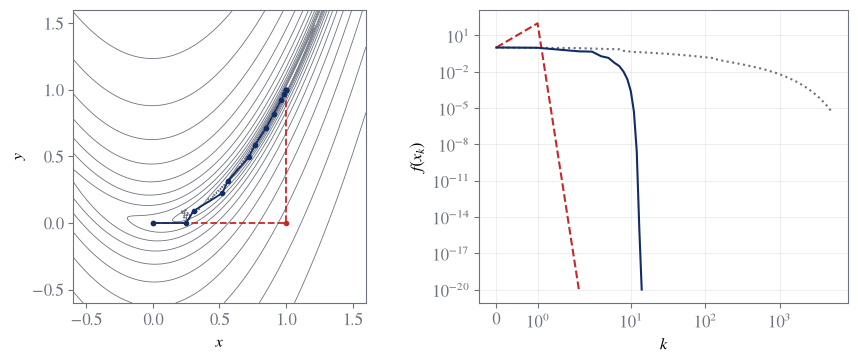

In [18]:
f, grad, hess = rosenbrock()
_, full = newton(f, grad, hess, [0, 0])
_, damped = newton(f, grad, hess, [0, 0], damped=True)
_, gd = gradient_descent(f, grad, [0, 0], max_iter=5000)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
u, v = np.meshgrid(np.linspace(-0.6, 1.6, 300), np.linspace(-0.6, 1.6, 300))
axes[0].contour(u, v, f([u, v]), levels=np.geomspace(0.05, 300, 14), colors=HSE['gray'], linewidths=0.6)
for h, color, style in [(gd, HSE['gray'], ':'), (full, HSE['accent'], '--'), (damped, HSE['blue'], '-')]:
    path = np.array(h['x'])
    axes[0].plot(path[:, 0], path[:, 1], style, color=color, lw=1.3, marker='o' if h is not gd else None, ms=3)
    axes[1].semilogy(range(len(h['f'])), np.maximum(h['f'], 1e-20), style, color=color, lw=1.5)
axes[0].set(xlabel=r'$x$', ylabel=r'$y$', aspect='equal')
axes[1].set(xlabel=r'$k$', ylabel=r'$f(x_k)$', xscale='symlog')
axes[1].grid(alpha=0.2)
fig.tight_layout()
save(fig, 'fig_newton')
plt.show()

### Quadratic convergence

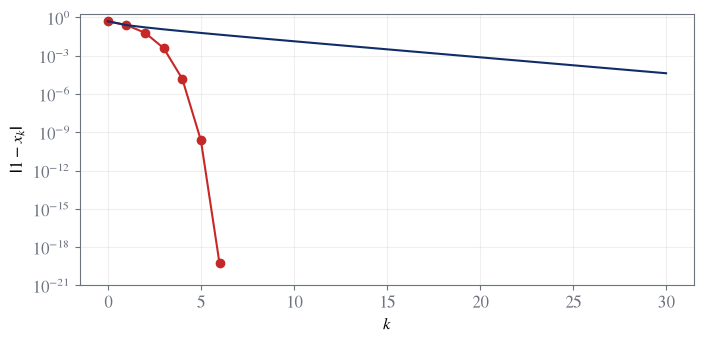

In [19]:
errors = [0.5]
for _ in range(6):
    errors.append(errors[-1] ** 2)
x, gd_errors = 0.5, [0.5]
for _ in range(30):
    x -= 0.25 * (1 - 1 / x)
    gd_errors.append(abs(1 - x))
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.semilogy(range(len(errors)), errors, 'o-', color=HSE['accent'], lw=1.5)
ax.semilogy(range(len(gd_errors)), gd_errors, '-', color=HSE['blue'], lw=1.5)
ax.set(xlabel=r'$k$', ylabel=r'$|1-x_k|$', ylim=(1e-21, 2))
ax.grid(alpha=0.2)
fig.tight_layout()
check('figures: Newton reaches 2^-64 in six steps', errors[6], 2.0 ** -64)
save(fig, 'fig_digits')
plt.show()

### A saddle

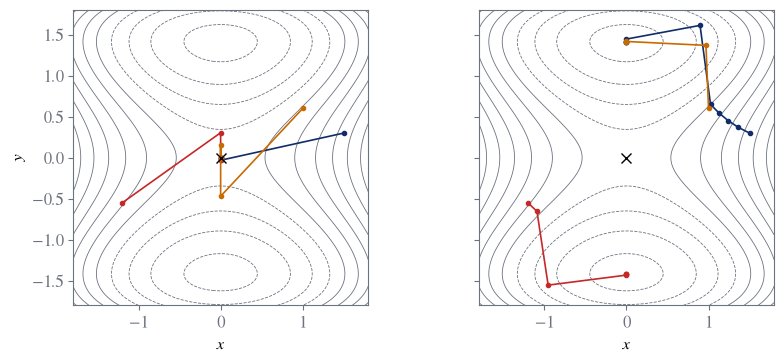

In [20]:
fq, gq, Hq = saddle
starts = [(1.5, 0.3), (-1.2, -0.55), (1.0, 0.6)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
u, v = np.meshgrid(np.linspace(-1.8, 1.8, 300), np.linspace(-1.8, 1.8, 300))
for ax, damped in zip(axes, (False, True)):
    ax.contour(u, v, fq([u, v]), levels=np.linspace(-0.9, 2.5, 14), colors=HSE['gray'], linewidths=0.6)
    for x0, color in zip(starts, (HSE['blue'], HSE['accent'], HSE['orange'])):
        _, h = newton(fq, gq, Hq, x0, damped=damped, max_iter=30)
        path = np.array(h['x'])
        ax.plot(path[:, 0], path[:, 1], 'o-', color=color, ms=3, lw=1.2)
        check(f"figures: {'safeguarded' if damped else 'full'} Newton from {x0} ends at a stationary point",
              np.linalg.norm(gq(path[-1])), 0, 1e-8)
    ax.plot([0], [0], 'x', color='black', ms=7)
    ax.set(xlabel=r'$x$', aspect='equal')
axes[0].set(ylabel=r'$y$')
fig.tight_layout()
save(fig, 'fig_saddle')
plt.show()

### BFGS on Rosenbrock's function

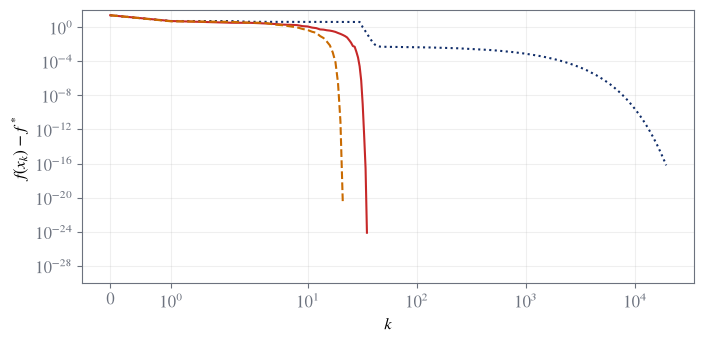

In [21]:
f, grad, hess = rosenbrock()
start = [-1.2, 1.0]
_, gd = gradient_descent(f, grad, start, tol=1e-8, max_iter=20_000)
_, bf = quasi_newton(f, grad, start, tol=1e-8)
_, nt = newton(f, grad, hess, start, tol=1e-8, damped=True)
check('figures: BFGS reaches the minimizer of Rosenbrock', bf['x'][-1], [1, 1], 1e-7)
check('figures: no BFGS pair is skipped on Rosenbrock', bf['skipped'], 0)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for h, color, style in [(gd, HSE['blue'], ':'), (bf, HSE['accent'], '-'), (nt, HSE['orange'], '--')]:
    ax.semilogy(range(len(h['f'])), np.maximum(h['f'], 1e-30), style, color=color, lw=1.5)
ax.set(xlabel=r'$k$', ylabel=r'$f(x_k)-f^*$', xscale='symlog', ylim=(1e-30, 1e2))
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, 'fig_bfgs')
plt.show()

### Work on a logistic regression

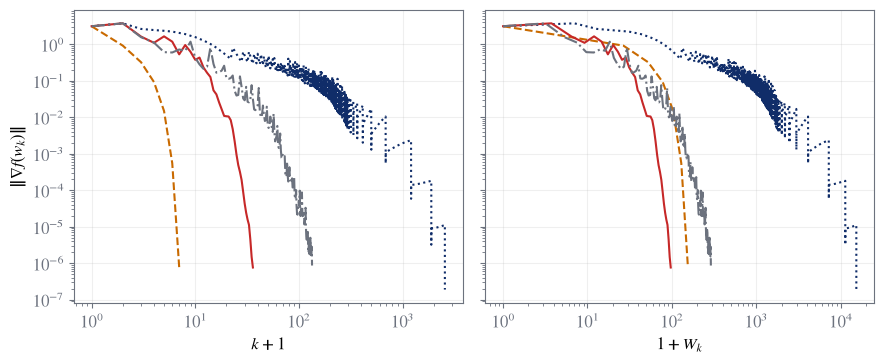

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
styles = {'gd': (HSE['blue'], ':'), 'newton': (HSE['orange'], '--'), 'bfgs': (HSE['accent'], '-'),
          'lbfgs': (HSE['gray'], '-.')}
for name, h in cost_runs.items():
    color, style = styles[name]
    k = np.arange(len(h['grad_norm']))
    per_step = work[name] / max(1, len(h['grad_norm']) - 1)
    axes[0].loglog(k + 1, h['grad_norm'], style, color=color, lw=1.5)
    axes[1].loglog(1 + per_step * k, h['grad_norm'], style, color=color, lw=1.5)
axes[0].set(xlabel=r'$k+1$', ylabel=r'$\|\nabla f(w_k)\|$')
axes[1].set(xlabel=r'$1+W_k$')
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, 'fig_cost')
plt.show()

## 6. Handout and cheat sheet

The content is rendered into the English and Russian LaTeX sources.

In [23]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    # toFixed of JavaScript: a tie goes away from zero
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "\u2212" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "\u2212" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    # a plain nonnegative number stays text; anything with a sign or TeX goes into math
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    """The segmenter of render.js: $$display$$, $inline$, \\$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and the markup \\textbf, \\emph, \\texttt."""
    # displays with only spaces between them are stacked in one: two \[ \] in a row leave an empty line
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace("\u00a0", " ").replace("\u202f", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        # tokens and code spans are set aside before escaping and restored after the markup
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace("\u00a0", "~").replace("\u202f", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03\u00a0]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; while a Russian string is missing, the English one is set with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


def cell_kind(cell):
    segs = tex_segments(cell)
    if len(segs) == 1 and segs[0][0] == "math":
        body = TOKEN.sub("v", segs[0][1]).strip()
        if re.fullmatch(r"v|-?\d+(\.\d+)?", body):
            return "num"
    if all(k != "text" or re.fullmatch(r"[\s,]*", v) for k, v in segs):
        return "math"
    return "text"


def cell_width(cell, data, lang):
    """Printed width of a table cell in characters; a TeX command counts as one, braces as none."""
    w = 0
    for kind, seg in tex_segments(cell):
        if kind == "text":
            seg = TOKEN.sub(lambda m: tex_value(value_at(data, m.group(1)), lang, False), seg)
            w += len(seg.replace("**", "").replace("*", "").replace("`", ""))
        else:
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = re.sub(r"\\[A-Za-z]+|\\.", "c", body).replace("{", "").replace("}", "")
            w += 2 + len(body)
    return w


# room the paragraph columns must leave: a character of a column that keeps its natural width takes at
# most this fraction of the 466.6pt text width at \small, and 2\tabcolsep between two columns takes 12pt
CHAR_SHARE = {"text": 0.012, "math": 0.010, "num": 0.010}
GAP_SHARE = 0.026


def table_spec(head, rows, data, lang):
    ncol = len(head)
    kinds, widths = [], []
    for j in range(ncol):
        body = [r[j] for r in rows]
        ks = {cell_kind(c) for c in body}
        kinds.append("num" if ks == {"num"} else "math" if ks <= {"num", "math"} else "text")
        widths.append(max(cell_width(c, data, lang) for c in [head[j]] + body))
    total = sum(widths)
    spec = ["r" if k == "num" else "l" for k in kinds]
    # a wide table gets paragraph columns for its long text columns, or for its widest column
    if total > 70:
        wide = [j for j in range(ncol) if kinds[j] == "text" and widths[j] >= 18]
        if wide:
            shares = {j: 0.9 * widths[j] / total for j in wide}
        else:
            wide = [max(range(ncol), key=lambda k: widths[k])]
            shares = {wide[0]: 0.4}
        natural = sum(CHAR_SHARE[kinds[j]] * widths[j] for j in range(ncol) if j not in wide)
        budget = 0.98 - GAP_SHARE * (ncol - 1) - natural
        # the fractions are scaled into the budget and rounded down, so their sum plus the natural
        # columns stays inside \linewidth however the estimate of the natural ones errs; a column raised
        # to the floor of 0.15 takes its room from the others
        scale = min(1.0, budget / sum(shares.values()))
        low = [j for j in wide if shares[j] * scale < 0.15]
        high = sum(shares[j] for j in wide if j not in low) * scale
        squeeze = min(1.0, (budget - 0.15 * len(low)) / high) if high else 1.0
        for j in wide:
            share = f"{0.15 if j in low else int(100 * shares[j] * scale * squeeze) / 100:g}"
            # \hspace{0pt} lets the first word of a cell be hyphenated
            spec[j] = r">{\raggedright\arraybackslash\hspace{0pt}}p{" + share + r"\linewidth}"
    return "@{}" + "".join(spec) + "@{}"


def table_tex(block, data, lang):
    pick = lambda c: c.get(lang) or c["en"]
    head, rows = [pick(c) for c in block["head"]], [[pick(c) for c in row] for row in block["rows"]]
    spec = table_spec(head, rows, data, lang)
    line = lambda cells: " & ".join(tr(c, data, lang, inline=True) for c in cells) + r" \\"
    body = [line(r) for r in block["rows"]]
    if len(body) > 10:
        return "\n".join([r"\begingroup\small", r"\begin{longtable}{" + spec + "}", r"\toprule",
                          line(block["head"]), r"\midrule", r"\endhead", *body, r"\bottomrule",
                          r"\end{longtable}", r"\endgroup"])
    return "\n".join([r"\begin{center}\small", r"\begin{tabular}{" + spec + "}", r"\toprule",
                      line(block["head"]), r"\midrule", *body, r"\bottomrule", r"\end{tabular}",
                      r"\end{center}"])


FIG_WIDTH = {'fig_newton': 0.95, 'fig_digits': 0.85, 'fig_saddle': 0.95, 'fig_bfgs': 0.85, 'fig_cost': 0.95}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 05", "page": "Theory handout",
           "topic": "Second-Order and Quasi-Newton Methods",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026–2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 05 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 5", "page": "Конспект теории",
           "topic": "Методы второго порядка и квазиньютоновские методы",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026–2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 5",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему",
           "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ", "convention": "Обозначения",
           "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t == "table":
        return table_tex(b, data, lang)
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        # a step quotes numbers that cannot be hyphenated: let the spaces stretch instead
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))


LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 05: theory handout (<<language>>).
% Generated by checks/05. Second-Order and Quasi-Newton Methods.ipynb from web/05/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
% a heading keeps a few lines under it on its page: a breakable box right after it would otherwise leave it alone
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
% a display wider than the line is set as a centred paragraph that may break after a relation
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 05: one-page cheat sheet (<<language>>).
% Generated by checks/05. Second-Order and Quasi-Newton Methods.ipynb from web/05/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

% Page style: the author and the license in the footer.
\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

% Compact layout.
\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 528 lines, unchanged
Theory_ru.tex: 532 lines, unchanged
Cheatsheet_en.tex: 158 lines, unchanged
Cheatsheet_ru.tex: 163 lines, unchanged


## 7. Content consistency

Both languages, tokens, answer fields, figures, links and generated sources are checked against the saved content.

In [24]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = [f"{b}{i}" for b in "ABC" for i in (1, 2, 3)]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    """(where, lang, text) for every {"en", "ru"} pair; a pair without ru goes to untranslated,
    any other shape of visible text to problems."""
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    """Paths of Cyrillic text other than the ru half of a pair and data leaves named ...Ru."""
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    """('text' | 'math' | 'display', piece) in order; None when a $ is not closed."""
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |–)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|–)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", "5", SEMINAR}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    """Page count from the /Type /Pages dictionaries, also inside compressed object streams."""
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [25]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-05", DOCS[name].get("id"), "seminar-05")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/05/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to C3", sorted(pub_problems) if pub_problems else PROBLEM_IDS,
      PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full, with their answer specs; "
      "the other problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "A3", "B2", "B3", "C2", "C3"],
       ["A2", "A3", "B2", "B3", "C2", "C3"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/05/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/05/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/05 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the five figures are written", sorted(FIGURES),
      ["fig_bfgs", "fig_cost", "fig_digits", "fig_newton", "fig_saddle"])

# the LaTeX sources against a generation from the files as they are now, then their PDFs
try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
INPUTREF = re.compile(r"\\input\{([^{}]+)\}")
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [THEORY / f"{s.removesuffix('.tex')}.tex" for s in INPUTREF.findall(text)]
    sources += [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 191 strings, untranslated: 0; students: 206 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 12, Theory_ru 12, Cheatsheet_en 1, Cheatsheet_ru 1


## 8. Summary

In [26]:
failed = [c for c in CHECKS if not c['passed']]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")


321 of 321 checks passed


## 9. Export

Only public numerical data are exported to the page.

In [27]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar05_data.js: unchanged (5505 bytes)
